<a href="https://colab.research.google.com/github/Samumishu18/Optativa-IA/blob/main/Copia_de_pr%C3%A1ctica_2_3_teachable_machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

En esta práctica se debe exportar el modelo que se genera en Teachable Machine.

A la hora de exportar el modelo, se puede exportar para Tensorflow.

También viene un fragmento de código para usar el modelo:

```
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

```

**Tarea**: subir 3 imágenes propias (una clara, una ambigua, una que no pertenezca a ninguna categoría) y anotar qué predice y con qué confianza.

**Antes de empezar:** ejecuta las celdas de arriba a abajo. La primera celda de código te pedirá los archivos `keras_model.h5` (o `keras_Model.h5`) y `labels.txt` exportados de Teachable Machine. Después, en cada ejercicio, subirás una imagen distinta.

**¡Ojo!** Se usa una versión de Keras compatible con los modelos `.h5` de Teachable Machine.

In [2]:
# Instala Keras compatible con los modelos clásicos de Teachable Machine.
%pip -q install tf-keras

import os
from pathlib import Path
from google.colab import files

# La variable debe configurarse antes de importar TensorFlow.
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf
import tf_keras

print("TensorFlow:", tf.__version__)
print("Keras compatible:", tf_keras.__version__)

# Si todavía no están los archivos, se solicitan mediante el botón de Colab.
modelos = list(Path(".").glob("*.h5"))
if not modelos or not Path("labels.txt").exists():
    print("Sube los dos archivos exportados: keras_model.h5 y labels.txt")
    files.upload()

modelos = list(Path(".").glob("*.h5"))
if not modelos:
    raise FileNotFoundError("No se ha subido el modelo .h5")
if not Path("labels.txt").exists():
    raise FileNotFoundError("No se ha subido labels.txt")

# Se acepta cualquiera de los nombres habituales del modelo.
modelo_archivo = next((p for p in modelos if p.name.lower() == "keras_model.h5"), modelos[0])
model = tf_keras.models.load_model(str(modelo_archivo), compile=False)
print("¡Modelo cargado!", modelo_archivo.name)

TensorFlow: 2.21.0
Keras compatible: 2.21.0
¡Modelo cargado! keras_model.h5


In [3]:
# Función común que permite subir y clasificar cada una de las tres imágenes.
from io import BytesIO
from PIL import Image, ImageOps
from IPython.display import display
import numpy as np
from google.colab import files

with open("labels.txt", encoding="utf-8") as archivo:
    clases = [linea.strip().split(" ", 1)[-1] for linea in archivo if linea.strip()]

def probar_imagen(tipo):
    print("Sube ahora la imagen:", tipo)
    subida = files.upload()
    if not subida:
        raise ValueError("No has subido ninguna imagen")

    nombre, contenido = next(iter(subida.items()))
    imagen = Image.open(BytesIO(contenido)).convert("RGB")
    vista = imagen.copy()
    vista.thumbnail((320, 320))
    display(vista)

    # Teachable Machine usa imágenes de 224x224 y valores entre -1 y 1.
    imagen = ImageOps.fit(imagen, (224, 224), method=Image.Resampling.LANCZOS)
    datos = np.asarray(imagen, dtype=np.float32)
    datos = (datos / 127.5) - 1
    datos = np.expand_dims(datos, axis=0)

    probabilidades = model.predict(datos, verbose=0)[0]
    indice = int(np.argmax(probabilidades))
    clase = clases[indice]
    porcentaje = float(probabilidades[indice]) * 100

    print(f"Archivo: {nombre}")
    print(f"Predicción: {clase}")
    print(f"Confianza: {porcentaje:.2f}%")

    return {"Tipo": tipo, "Imagen": nombre, "Predicción": clase, "Confianza": f"{porcentaje:.2f}%"}

print("Preparado para probar las tres imágenes.")

Preparado para probar las tres imágenes.


Sube ahora la imagen: Clara.jpg


Saving Clara.jpg to Clara (1).jpg


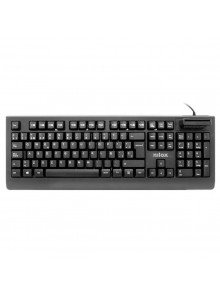

Archivo: Clara (1).jpg
Predicción: Teclado
Confianza: 99.99%


In [4]:
# EJERCICIO 1: imagen clara (un ratón o un teclado reconocible).
resultado_clara = probar_imagen("Clara.jpg")

Sube ahora la imagen: Ambigua.png


Saving Ambigua.png to Ambigua.png


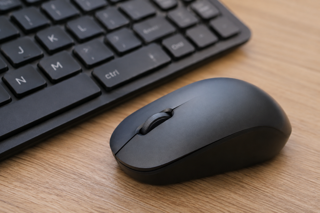

Archivo: Ambigua.png
Predicción: Raton
Confianza: 73.33%


In [5]:
# EJERCICIO 2: imagen ambigua (que pueda confundirse con varias clases).
resultado_ambigua = probar_imagen("Ambigua.png")

Sube ahora la imagen: Fuera de la categoria.jpg


Saving Fuera de la categoria.jpg to Fuera de la categoria.jpg


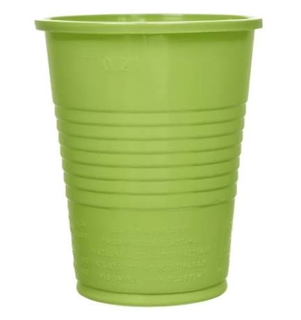

Archivo: Fuera de la categoria.jpg
Predicción: Raton
Confianza: 69.38%

RESUMEN DE LAS 3 PRUEBAS


,Tipo,Imagen,Predicción,Confianza
0,Clara.jpg,Clara (1).jpg,Teclado,99.99%
1,Ambigua.png,Ambigua.png,Raton,73.33%
2,Fuera de la categoria.jpg,Fuera de la categoria.jpg,Raton,69.38%


In [6]:
# EJERCICIO 3: imagen diferente (por ejemplo, una planta).
resultado_diferente = probar_imagen("Fuera de la categoria.jpg")

# Tabla final con la predicción y la confianza de cada prueba.
print("\nRESUMEN DE LAS 3 PRUEBAS")
import pandas as pd
display(pd.DataFrame([resultado_clara, resultado_ambigua, resultado_diferente]))

**¿Cómo se usa el modelo exportado? ¿Cómo se comporta?**

---



**Respuesta:**

El modelo exportado se utiliza cargando los archivos `keras_model.h5` y `labels.txt` en Python. Después se introduce una imagen, se adapta al tamaño que necesita el modelo (224 × 224 píxeles) y se obtiene una predicción con su porcentaje de confianza.

Con una imagen clara de ratón o teclado, se espera que el modelo acierte y tenga una confianza alta si ha sido bien entrenado. Con una imagen ambigua puede confundirse y dar una confianza menor o elegir la categoría equivocada. Con una imagen que no pertenece a ninguna de las dos categorías, el modelo seguirá intentando clasificarla como ratón o teclado, porque solo conoce las clases con las que lo entrenamos.

**Conclusión:** el modelo reconoce patrones aprendidos durante el entrenamiento, pero no comprende lo que aparece en la imagen como una persona. Un porcentaje alto de confianza no garantiza que la clasificación sea correcta, especialmente ante imágenes distintas de las usadas al entrenarlo. Los resultados concretos de las tres pruebas aparecen en la tabla generada al ejecutar las celdas anteriores.